# Cold Chain Forecasting — Air Temperature & Humidity (LSTM, PyTorch)

Predict the next **30 minutes** of `t_air_c` and `rh_pct` from the previous **120 minutes** of sensor readings.

**Critical structural note:** this dataset is **200 independent trips**, not one continuous time series.
Every interpolation, rolling op, and sliding window must be done **inside `groupby("trip_id")`**.
A window that spans the end of one trip and the start of the next describes a physical transition
that never happened.

## 1. Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Window configuration
N_PAST   = 120   # minutes of history fed to the model
N_FUTURE = 30    # minutes to forecast

# Shortest trip in the data is 241 rows, so N_PAST + N_FUTURE must stay under 241
assert N_PAST + N_FUTURE <= 241, "Window too long - some trips would be dropped entirely"

device: cuda


In [3]:
CSV_PATH = "data/coldchain_sensors.csv" 

coldChainDF = pd.read_csv(CSV_PATH)
print(coldChainDF.shape)
coldChainDF.head()

(109563, 12)


,trip_id,minute,t_air_c,rh_pct,t_ambient_c,rh_ambient_pct,door_open,vehicle_moving,compressor_on,defrost_on,hour_of_day,split
0,TRIP_0000,0,5.7,86.4,31.8,43.7,0,1,1,0,7.273,val
1,TRIP_0000,1,5.2,88.4,31.8,44.5,0,1,1,0,7.289,val
2,TRIP_0000,2,5.3,85.4,31.6,43.4,0,1,1,0,7.306,val
3,TRIP_0000,3,5.0,85.3,31.7,43.3,0,1,1,0,7.323,val
4,TRIP_0000,4,4.9,84.6,32.1,45.1,0,1,1,0,7.339,val


In [4]:
print("trips:", coldChainDF.trip_id.nunique())
print("trips per split:")
print(coldChainDF.groupby("split").trip_id.nunique())

# Each trip must live in exactly one split (this is what makes the split leak-free)
assert (coldChainDF.groupby("trip_id").split.nunique() == 1).all()

# Sampling must be exactly 1 minute with no gaps inside a trip
diffs = coldChainDF.groupby("trip_id")["minute"].diff().dropna().unique()
print("minute diffs:", diffs)
assert set(diffs) == {1.0}

print("\nmissing values:")
print(coldChainDF.isna().sum()[lambda s: s > 0])

trips: 200
trips per split:
split
test      30
train    140
val       30
Name: trip_id, dtype: int64
minute diffs: [1.]

missing values:
t_air_c    344
rh_pct     344
dtype: int64


## 2. Handle missing values (per trip)

`t_air_c` and `rh_pct` are the only columns with gaps, and they always go missing **together**
(sensor dropout, not independent noise). The gaps are 344 values across 148 trips, in runs of
only 1–2 minutes — short enough that linear interpolation is safe.

The `groupby` is what keeps the interpolation from bleeding the tail of one trip into the head
of the next.

In [5]:
TARGETS = ["t_air_c", "rh_pct"]

# Inspect gap run lengths before deciding to interpolate
flag = coldChainDF.t_air_c.isna()
runs = (flag != flag.shift()).cumsum()[flag].value_counts().value_counts().sort_index()
print("gap run lengths (length -> count):")
print(runs)

coldChainDF[TARGETS] = (
    coldChainDF.groupby("trip_id")[TARGETS]
    .transform(lambda s: s.interpolate(limit_direction="both"))
)

assert coldChainDF[TARGETS].isna().sum().sum() == 0
print("\nno missing values remaining")

gap run lengths (length -> count):
count
1    340
2      2
Name: count, dtype: int64

no missing values remaining


## 3. Cyclical encoding of `hour_of_day`

`hour_of_day` runs 0–24 and wraps around 76 times in this dataset. Fed in raw, the model would
treat 23.9 and 0.1 as maximally far apart when they are one minute apart. Sine/cosine encoding
puts them next to each other on a circle.

In [6]:
coldChainDF["hod_sin"] = np.sin(2 * np.pi * coldChainDF.hour_of_day / 24)
coldChainDF["hod_cos"] = np.cos(2 * np.pi * coldChainDF.hour_of_day / 24)

coldChainDF[["hour_of_day", "hod_sin", "hod_cos"]].head()

,hour_of_day,hod_sin,hod_cos
0,7.273,0.944977,-0.327135
1,7.289,0.943599,-0.331091
2,7.306,0.942116,-0.335287
3,7.323,0.940614,-0.339477
4,7.339,0.939184,-0.343414


## 4. Feature groups

Three kinds of column, treated differently at scaling time:

- **Continuous** — standardized.
- **Binary flags** — left alone. Standardizing 0/1 columns just adds noise and makes them
  harder to interpret.
- **Cyclical** — already in [-1, 1], leave as-is.

This is the **past-only** formulation: the model sees the last `N_PAST` minutes of *everything*
and predicts the next `N_FUTURE` minutes of temp and humidity.

In [7]:
CONT_FEATS = ["t_air_c", "rh_pct", "t_ambient_c", "rh_ambient_pct"]
BIN_FEATS  = ["door_open", "vehicle_moving", "compressor_on", "defrost_on"]
CYC_FEATS  = ["hod_sin", "hod_cos"]

FEATURES = CONT_FEATS + BIN_FEATS + CYC_FEATS
N_FEATURES = len(FEATURES)

print(f"{N_FEATURES} input features:", FEATURES)
print("targets:", TARGETS)

10 input features: ['t_air_c', 'rh_pct', 't_ambient_c', 'rh_ambient_pct', 'door_open', 'vehicle_moving', 'compressor_on', 'defrost_on', 'hod_sin', 'hod_cos']
targets: ['t_air_c', 'rh_pct']


## 5. Scaling — fit on train rows only

Two separate scalers:

- `feat_scaler` for the continuous inputs.
- `targ_scaler` for the two targets alone, so predictions can be inverted back to °C and %RH
  without slicing columns out of a wider scaler.

Both are fit on **train rows only**, then applied to all three splits. Fitting on the full frame
is the single most common leak in this kind of pipeline.

In [8]:
train_mask = coldChainDF.split == "train"

feat_scaler = StandardScaler().fit(coldChainDF.loc[train_mask, CONT_FEATS])
targ_scaler = StandardScaler().fit(coldChainDF.loc[train_mask, TARGETS])

scaled = coldChainDF.copy()
scaled[CONT_FEATS] = feat_scaler.transform(coldChainDF[CONT_FEATS])

# Scaled copies of the targets, kept in separate columns so the originals stay readable
Y_COLS = ["y_t_air", "y_rh"]
scaled[Y_COLS] = targ_scaler.transform(coldChainDF[TARGETS])

scaled[CONT_FEATS + Y_COLS].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
t_air_c,0.035106,0.994527,-2.109665,6.250751
rh_pct,0.025986,0.969864,-3.637361,4.639460
t_ambient_c,0.052379,1.030524,-1.987588,3.043009
rh_ambient_pct,-0.051578,0.978990,-2.094753,2.468990
y_t_air,0.035106,0.994527,-2.109665,6.250751
y_rh,0.025986,0.969864,-3.637361,4.639460


## 6. Build windows inside each trip

`make_windows` loops over trips within a single split and never crosses a trip boundary.

It also returns `last_obs` — the final observed target value in each input window. That is the
persistence baseline prediction, and carrying it alongside the windows saves recomputing it later.

In [9]:
def make_windows(df, split, n_past=N_PAST, n_future=N_FUTURE):
    """Slide windows within each trip of `split`. Never crosses trip boundaries."""
    X, y, last_obs = [], [], []
    subset = df[df.split == split]

    for _, g in subset.groupby("trip_id", sort=False):
        feats = g[FEATURES].values
        targs = g[Y_COLS].values
        n_windows = len(g) - n_past - n_future + 1
        if n_windows <= 0:
            continue  # trip too short for this window size
        for i in range(n_windows):
            X.append(feats[i : i + n_past])
            y.append(targs[i + n_past : i + n_past + n_future])
            last_obs.append(targs[i + n_past - 1])

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(last_obs, dtype=np.float32),
    )


X_train, y_train, last_train = make_windows(scaled, "train")
X_val,   y_val,   last_val   = make_windows(scaled, "val")
X_test,  y_test,  last_test  = make_windows(scaled, "test")

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s} X {X.shape}  y {y.shape}")

train X (55092, 120, 10)  y (55092, 30, 2)
val   X (12488, 120, 10)  y (12488, 30, 2)
test  X (12183, 120, 10)  y (12183, 30, 2)


## 7. Persistence baseline — establish this before training

"The next 30 minutes look exactly like the last observed minute."

Cold chain air temperature is heavily autocorrelated, so this baseline is genuinely strong.
It is the number the LSTM has to beat to have learned anything worth having.

In [10]:
def inverse_targets(arr):
    """(samples, n_future, 2) in scaled space -> original units."""
    flat = arr.reshape(-1, 2)
    return targ_scaler.inverse_transform(flat).reshape(arr.shape)


def report(y_true_scaled, y_pred_scaled, label):
    y_true = inverse_targets(y_true_scaled)
    y_pred = inverse_targets(y_pred_scaled)
    err = np.abs(y_true - y_pred)
    rmse = np.sqrt(((y_true - y_pred) ** 2).reshape(-1, 2).mean(axis=0))
    mae = err.reshape(-1, 2).mean(axis=0)
    print(f"{label}")
    print(f"  t_air_c  MAE {mae[0]:.4f} C     RMSE {rmse[0]:.4f}")
    print(f"  rh_pct   MAE {mae[1]:.4f} %RH   RMSE {rmse[1]:.4f}")
    return mae


# Repeat the last observed value across the whole forecast horizon
persist_test = np.repeat(last_test[:, None, :], N_FUTURE, axis=1)
baseline_mae = report(y_test, persist_test, "PERSISTENCE BASELINE (test)")

PERSISTENCE BASELINE (test)
  t_air_c  MAE 0.7574 C     RMSE 1.3163
  rh_pct   MAE 2.4309 %RH   RMSE 3.2554


## 8. PyTorch datasets and dataloaders

Wrap the numpy arrays in a plain `Dataset`. `pin_memory=True` and a larger batch on `DataLoader`
speed up GPU transfer if you have a GPU; harmless on CPU.

In [11]:
class WindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_ds = WindowDataset(X_train, y_train)
val_ds   = WindowDataset(X_val, y_val)
test_ds  = WindowDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=256,        shuffle=False, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=256,        shuffle=False, pin_memory=True)

print(f"train batches: {len(train_loader)}, val batches: {len(val_loader)}, test batches: {len(test_loader)}")

train batches: 861, val batches: 49, test batches: 48


## 9. Model

In [12]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, n_future, n_targets, hidden1=64, hidden2=32, dropout=0.2):
        super().__init__()
        self.n_future = n_future
        self.n_targets = n_targets

        self.lstm1 = nn.LSTM(n_features, hidden1, batch_first=True)
        self.drop1 = nn.Dropout(dropout)
        self.lstm2 = nn.LSTM(hidden1, hidden2, batch_first=True)
        self.drop2 = nn.Dropout(dropout)
        self.head  = nn.Linear(hidden2, n_future * n_targets)

    def forward(self, x):
        # x: (batch, N_PAST, n_features)
        out, _ = self.lstm1(x)
        out = self.drop1(out)
        out, (h_n, _) = self.lstm2(out)
        out = self.drop2(h_n[-1])          # last layer's final hidden state: (batch, hidden2)
        out = self.head(out)               # (batch, n_future * n_targets)
        return out.view(-1, self.n_future, self.n_targets)


model = LSTMForecaster(N_FEATURES, N_FUTURE, len(TARGETS)).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\ntrainable parameters: {n_params:,}")

LSTMForecaster(
  (lstm1): LSTM(10, 64, batch_first=True)
  (drop1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 32, batch_first=True)
  (drop2): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=32, out_features=60, bias=True)
)

trainable parameters: 33,980


## 10. Train

Huber loss (`nn.SmoothL1Loss`) is less twitchy than MSE around the sharp door-open / defrost
spikes in this data. Early stopping and LR reduction are done manually — PyTorch has no built-in
`Callback` API, so the loop tracks `best_val_loss` itself and restores the best weights at the end.

`validation_data` is a **separate loader built from the `split` column**, not a random slice — do
not shuffle trips into it. That would hand you a validation set that no longer matches what the
dataset author intended when they assigned `split`.

In [13]:
import copy

EPOCHS = 100
PATIENCE = 10          # early stopping
LR_PATIENCE = 5         # ReduceLROnPlateau
LR_FACTOR = 0.5
MIN_LR = 1e-5

criterion = nn.SmoothL1Loss()   # Huber loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=MIN_LR
)


def run_epoch(loader, model, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, total_mae, n = 0.0, 0.0, 0

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = criterion(preds, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            bs = xb.size(0)
            total_loss += loss.item() * bs
            total_mae  += torch.abs(preds - yb).mean().item() * bs
            n += bs

    return total_loss / n, total_mae / n


history = {"loss": [], "val_loss": [], "mae": [], "val_mae": []}
best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_mae = run_epoch(train_loader, model, criterion, optimizer)
    val_loss, val_mae     = run_epoch(val_loader, model, criterion, optimizer=None)
    scheduler.step(val_loss)

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["mae"].append(train_mae)
    history["val_mae"].append(val_mae)

    improved = val_loss < best_val_loss - 1e-6
    if improved:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    current_lr = optimizer.param_groups[0]["lr"]
    print(f"epoch {epoch:3d}  loss {train_loss:.4f}  val_loss {val_loss:.4f}  "
          f"mae {train_mae:.4f}  val_mae {val_mae:.4f}  lr {current_lr:.2e}"
          + ("  *" if improved else ""))

    if epochs_no_improve >= PATIENCE:
        print(f"\nearly stopping at epoch {epoch} (no improvement for {PATIENCE} epochs)")
        break

model.load_state_dict(best_state)   # restore_best_weights equivalent
print(f"\nrestored best weights, val_loss = {best_val_loss:.4f}")

epoch   1  loss 0.1118  val_loss 0.0742  mae 0.3396  val_mae 0.2640  lr 1.00e-03  *
epoch   2  loss 0.0839  val_loss 0.0719  mae 0.2920  val_mae 0.2606  lr 1.00e-03  *
epoch   3  loss 0.0806  val_loss 0.0707  mae 0.2855  val_mae 0.2588  lr 1.00e-03  *
epoch   4  loss 0.0781  val_loss 0.0708  mae 0.2809  val_mae 0.2602  lr 1.00e-03
epoch   5  loss 0.0765  val_loss 0.0726  mae 0.2780  val_mae 0.2649  lr 1.00e-03
epoch   6  loss 0.0748  val_loss 0.0778  mae 0.2750  val_mae 0.2751  lr 1.00e-03
epoch   7  loss 0.0730  val_loss 0.0827  mae 0.2719  val_mae 0.2795  lr 1.00e-03
epoch   8  loss 0.0721  val_loss 0.0809  mae 0.2705  val_mae 0.2776  lr 1.00e-03
epoch   9  loss 0.0702  val_loss 0.0857  mae 0.2678  val_mae 0.2863  lr 5.00e-04
epoch  10  loss 0.0669  val_loss 0.1022  mae 0.2620  val_mae 0.3075  lr 5.00e-04
epoch  11  loss 0.0659  val_loss 0.0942  mae 0.2605  val_mae 0.2973  lr 5.00e-04
epoch  12  loss 0.0644  val_loss 0.0980  mae 0.2582  val_mae 0.3020  lr 5.00e-04
epoch  13  loss 0.0

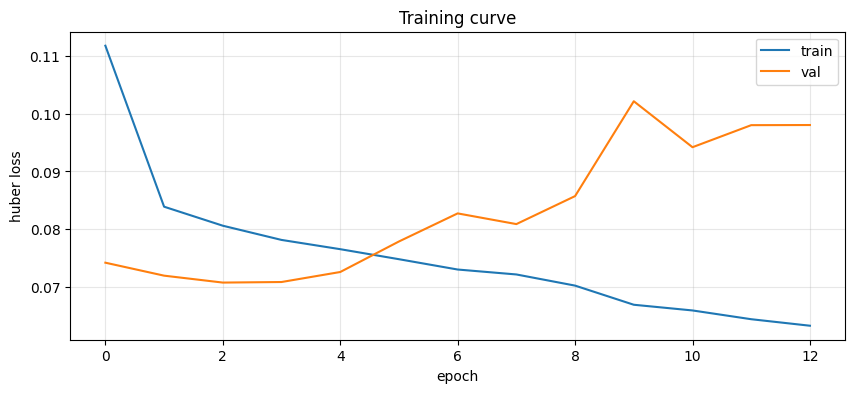

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(history["loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("huber loss"); plt.legend(); plt.title("Training curve")
plt.grid(alpha=0.3)
plt.show()

## 11. Evaluate against the baseline

In [15]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        preds.append(model(xb).cpu().numpy())
y_pred = np.concatenate(preds, axis=0)

model_mae = report(y_test, y_pred, "LSTM (test)")
print()
baseline_mae = report(y_test, persist_test, "PERSISTENCE (test)")

print("\nimprovement over baseline:")
for i, name in enumerate(TARGETS):
    delta = (baseline_mae[i] - model_mae[i]) / baseline_mae[i] * 100
    verdict = "beats baseline" if delta > 0 else "WORSE THAN BASELINE"
    print(f"  {name:10s} {delta:+6.1f}%   {verdict}")

LSTM (test)
  t_air_c  MAE 0.6636 C     RMSE 1.2559
  rh_pct   MAE 1.9599 %RH   RMSE 2.6769

PERSISTENCE (test)
  t_air_c  MAE 0.7574 C     RMSE 1.3163
  rh_pct   MAE 2.4309 %RH   RMSE 3.2554

improvement over baseline:
  t_air_c     +12.4%   beats baseline
  rh_pct      +19.4%   beats baseline


### Error by forecast horizon

Aggregate MAE hides the shape of the problem. Error should grow with how far ahead you are
predicting; if it is flat, the model is likely just echoing the last input value.

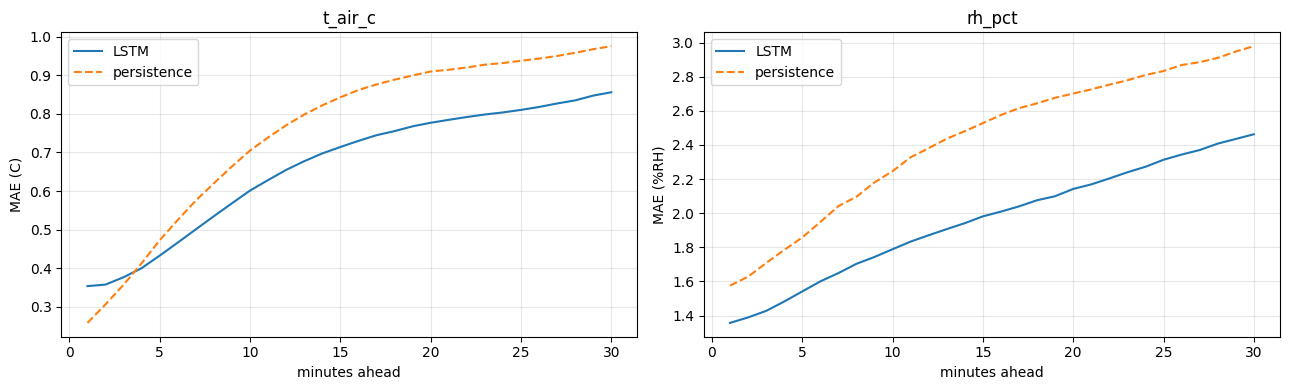

In [16]:
y_true_inv = inverse_targets(y_test)
y_pred_inv = inverse_targets(y_pred)
persist_inv = inverse_targets(persist_test)

steps = np.arange(1, N_FUTURE + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (ax, name, unit) in enumerate(zip(axes, TARGETS, ["C", "%RH"])):
    ax.plot(steps, np.abs(y_true_inv[:, :, i] - y_pred_inv[:, :, i]).mean(axis=0), label="LSTM")
    ax.plot(steps, np.abs(y_true_inv[:, :, i] - persist_inv[:, :, i]).mean(axis=0), "--", label="persistence")
    ax.set_xlabel("minutes ahead"); ax.set_ylabel(f"MAE ({unit})")
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Spot-check a few forecasts

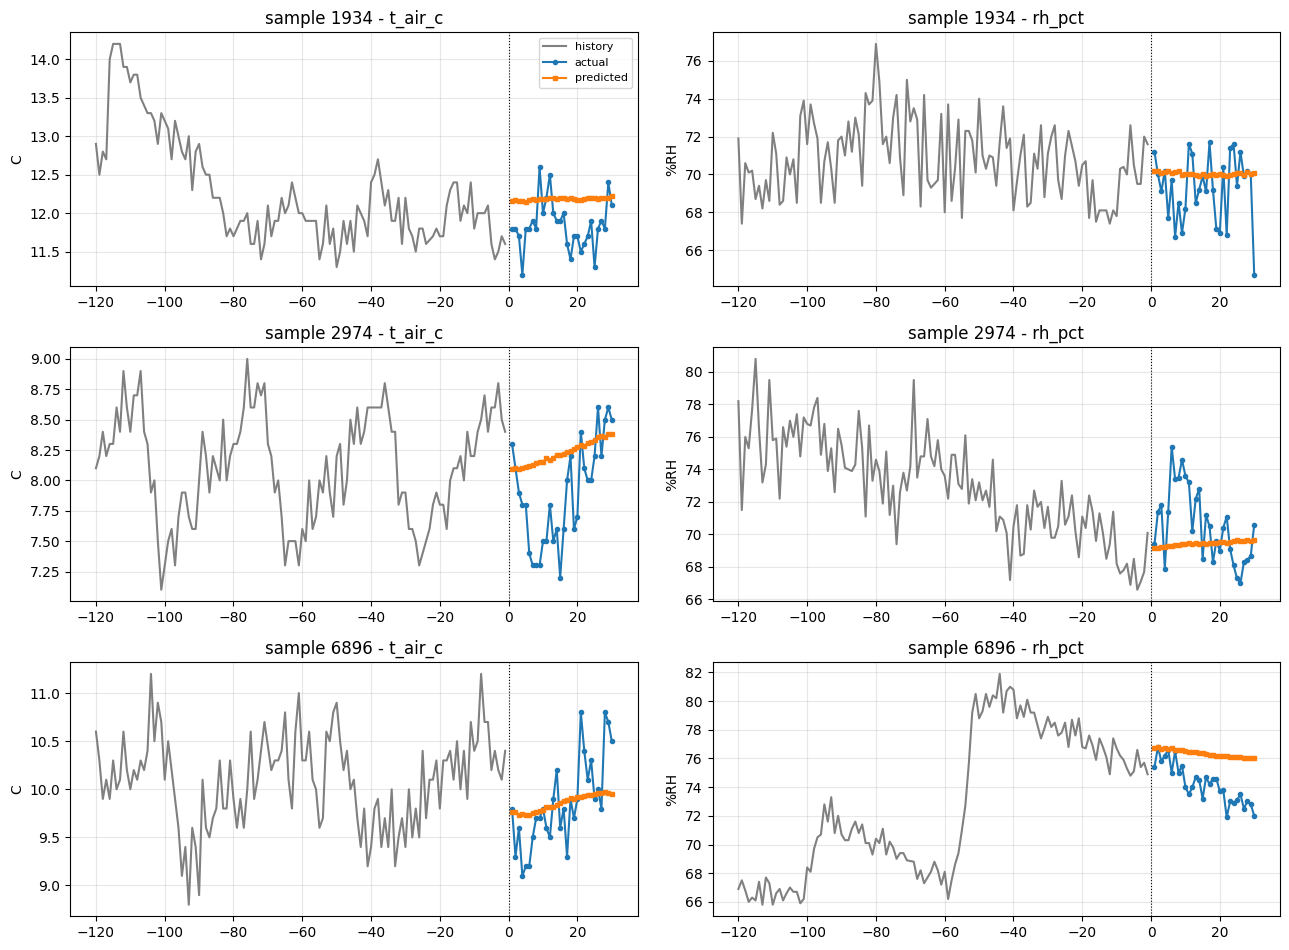

In [17]:
idx = np.random.choice(len(X_test), 3, replace=False)
fig, axes = plt.subplots(len(idx), 2, figsize=(13, 3.2 * len(idx)))

for r, j in enumerate(idx):
    hist = targ_scaler.inverse_transform(
        X_test[j][:, [FEATURES.index("t_air_c"), FEATURES.index("rh_pct")]]
    )
    for c, (name, unit) in enumerate(zip(TARGETS, ["C", "%RH"])):
        ax = axes[r, c]
        ax.plot(np.arange(-N_PAST, 0), hist[:, c], color="gray", label="history")
        ax.plot(steps, y_true_inv[j, :, c], "o-", ms=3, label="actual")
        ax.plot(steps, y_pred_inv[j, :, c], "s-", ms=3, label="predicted")
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.set_title(f"sample {j} - {name}"); ax.set_ylabel(unit); ax.grid(alpha=0.3)
        if r == 0 and c == 0:
            ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 12. Save model and scalers together

The scalers are not optional artifacts — without them the saved model produces numbers in
standardized space that cannot be converted back to °C or %RH.

`state_dict` + a small config dict is the portable PyTorch save pattern — it needs the model
class definition available at load time, which is why `config.json` also records the
constructor arguments.

In [18]:
import joblib, json, os

os.makedirs("artifacts", exist_ok=True)

torch.save(model.state_dict(), "artifacts/coldchain_lstm.pt")
joblib.dump({"feat_scaler": feat_scaler, "targ_scaler": targ_scaler}, "artifacts/scalers.joblib")

with open("artifacts/config.json", "w") as f:
    json.dump({
        "n_past": N_PAST, "n_future": N_FUTURE,
        "features": FEATURES, "cont_feats": CONT_FEATS, "targets": TARGETS,
        "n_features": N_FEATURES, "hidden1": 64, "hidden2": 32, "dropout": 0.2,
    }, f, indent=2)

print("saved to artifacts/")

# To reload later:
#   cfg = json.load(open("artifacts/config.json"))
#   model = LSTMForecaster(cfg["n_features"], cfg["n_future"], len(cfg["targets"]),
#                           cfg["hidden1"], cfg["hidden2"], cfg["dropout"])
#   model.load_state_dict(torch.load("artifacts/coldchain_lstm.pt", map_location=device))
#   model.eval()

saved to artifacts/


## Where to go if the baseline is hard to beat

`t_air_c` correlates only weakly with every other column in this file (the strongest is
`door_open` at 0.17). Nearly all of the signal lives in the target's own recent history, which
means the persistence baseline is strong and the exogenous sensors may earn less than expected.

Things worth trying, roughly in order of payoff:

1. **Predict the delta instead of the level.** Target `y[t+h] - y[t_last_observed]` and add the
   last value back at inference. This removes the level-matching work and forces the network to
   spend its capacity on the dynamics.
2. **Shorten the horizon.** 30 minutes out is a lot for minute-resolution data. Check the
   per-horizon plot — if the model only wins in the first 5–10 minutes, forecast that instead.
3. **Add engineered lags** — rolling means, and minutes-since-last-door-open / defrost-off. Event
   recency usually carries more signal than the raw binary flag.
4. **Widen `N_PAST`** to 180 or 240 if the compressor duty cycle is longer than 2 hours.
5. **Only then** make the network bigger. Capacity is rarely the binding constraint here.